Исследование заведений общественного питания г. Москвы


В открытом доступе имеются  данные о заведениях общественного питания г. Москва. Мы хотим провести анализ этих данных и дать рекомендации по открытию того или иного заведения

In [1]:
%pip install folium -U
from folium import Map, Choropleth, Marker, CustomIcon
from folium.plugins import MarkerCluster

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Импортируем необходимые библиотеки для анализа и визуализации
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import folium
from folium import Map, Choropleth
import warnings

# Отключаем предупреждения для чистоты вывода
warnings.filterwarnings('ignore')

# Настраиваем стиль графиков
sns.set_theme(style="whitegrid")

# Указываем путь к данным. 
# Используем относительный путь.
path_to_data = '../data/moscow_places.csv'

# Загружаем данные
try:
    data = pd.read_csv(path_to_data)
    print("Данные успешно загружены!")
    print(f"Размер датасета: {data.shape[0]} строк, {data.shape[1]} столбцов")
except FileNotFoundError:
    print(f"Ошибка: Файл не найден по пути {path_to_data}. Проверьте структуру папок.")

Данные успешно загружены!
Размер датасета: 8406 строк, 14 столбцов


Создадим необходимые функции для начертания графиков

In [3]:
def heatmap(data, index, columns, values, aggfunc, title):
    data = data.pivot_table(index=index, columns=columns, values=values, aggfunc=aggfunc)
    plt.figure(figsize=(12,6))
    plt.title(title)
    sns.heatmap(data, annot=True)
    plt.show()

In [4]:
def bar(data, index, values, aggfunc, title):
    fig = px.bar(data.pivot_table(index=index, values=values, aggfunc=aggfunc), title=title)
    fig.show()

In [5]:
def map(data, group, column, agg, title):
    rating_df = data.groupby(group, as_index=False)[column].agg(agg)

    # загружаем JSON-файл с границами округов Москвы
    state_geo = 'https://code.s3.yandex.net/data-analyst/admin_level_geomap.geojson'
    # moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
    moscow_lat, moscow_lng = 55.751244, 37.618423

    # создаём карту Москвы
    m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

    # создаём хороплет с помощью конструктора Choropleth и добавляем его на карту
    Choropleth(
        geo_data=state_geo,
        data=rating_df,
        columns=[group, column],
        key_on='feature.name',
        fill_color='YlGn',
        fill_opacity=0.8,
        legend_name=title,
    ).add_to(m)

    # выводим карту
    return m

Получим данные и загрузим их в рабочую среду.

In [6]:
try:
    data = pd.read_csv('../data/moscow_places.csv')
except:
    data= pd.read_csv('/datasets/moscow_places.csv')

In [7]:
data.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4.0
2,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45.0
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN
4,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148.0


Описание данных

name — название заведения;
address — адрес заведения;
category — категория заведения, например «кафе», «пиццерия» или «кофейня»;
hours — информация о днях и часах работы;
lat — широта географической точки, в которой находится заведение;
lng — долгота географической точки, в которой находится заведение;
rating — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
price — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
avg_bill — строка, которая хранит среднюю стоимость заказа в виде диапазона,
middle_avg_bill — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»,
middle_coffee_cup — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»,
chain — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
    0 — заведение не является сетевым
    1 — заведение является сетевым
district — административный район, в котором находится заведение, например Центральный административный округ;
seats — количество посадочных мест.

Проведем EDA

Посмотрим общую информацию и примеры данных:

In [8]:
data.shape

(8406, 14)

Мы получили 8406  строк и 14 столбцов

Проверим данные на наличие пропусков

In [9]:
data.isnull().sum()

name                    0
category                0
address                 0
district                0
hours                 536
lat                     0
lng                     0
rating                  0
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
chain                   0
seats                3611
dtype: int64

Как видим мы имеем большое количетво пропуском по ряду параметров (часы работы (hours), price — категория цен в заведении, avg_bill — строка, которая хранит среднюю стоимость заказа, middle_avg_bill — число с оценкой среднего чека, middle_coffee_cup — число с оценкой одной чашки капучино, seats — количество посадочных мест. Очевидно в данных все пропуски заменены на NaN вхождения

In [10]:
data.describe()

,lat,lng,rating,middle_avg_bill,middle_coffee_cup,chain,seats
count,8406.000000,8406.000000,8406.000000,3149.000000,535.000000,8406.000000,4795.000000
mean,55.750109,37.608570,4.229895,958.053668,174.721495,0.381275,108.421689
std,0.069658,0.098597,0.470348,1009.732845,88.951103,0.485729,122.833396
min,55.573942,37.355651,1.000000,0.000000,60.000000,0.000000,0.000000
25%,55.705155,37.538583,4.100000,375.000000,124.500000,0.000000,40.000000
50%,55.753425,37.605246,4.300000,750.000000,169.000000,0.000000,75.000000
75%,55.795041,37.664792,4.400000,1250.000000,225.000000,1.000000,140.000000
max,55.928943,37.874466,5.000000,35000.000000,1568.000000,1.000000,1288.000000


Дополним данные, создадим столбец с названием улицы где рсположено заведение "street'


In [11]:
data['street'] = data['address'].str.split(', ').str[1]

In [12]:
data.query('street.isna()').address.count()

np.int64(0)

Мы получили, что у всех заведений  определены улицы.

Дополним еще одним столбцом. Столбец с характристикой работает ли заведение круглосуточно и ежедневно "work_24_7". Заполним данные булевыми значениями содержащими True если заведение круглосуточное и False если оно таковым не является. Перед началом работы заполним пустоты в столбце hours.

In [13]:
data.hours = data.hours.fillna('неизвестно')
data["work_24_7"] = data['hours'].str.contains('ежедневно, круглосуточно')
print(str(data.hours.unique()))

<StringArray>
[                              'ежедневно, 10:00–22:00',
 'пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00–02:00',
                               'ежедневно, 09:00–22:00',
                               'ежедневно, 10:00–23:00',
                    'пн 15:00–04:00; вт-вс 15:00–05:00',
 'пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00–22:00',
                               'ежедневно, 12:00–00:00',
                             'ежедневно, круглосуточно',
                               'ежедневно, 10:00–21:00',
                                    'вт-сб 09:00–18:00',
 ...
    'пн-пт 09:00–23:00; сб 12:00–23:00; вс 10:00–23:00',
                               'ежедневно, 09:00–01:30',
                 'пн-пт 08:00–00:00; сб,вс 13:00–01:00',
                 'пн-пт 11:00–22:00; сб,вс 10:00–23:00',
                 'пн-пт 11:00–03:00; сб,вс 11:00–06:00',
    'пн 00:00–21:00; вт-сб 09:00–21:00; вс 00:00–21:00',
                 'пн-пт 07:00–20:00; сб,вс 09:00–19:00',
            

In [14]:
data.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7
0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN,улица Дыбенко,False
1,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4.0,улица Дыбенко,False
2,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45.0,Клязьминская улица,False
3,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN,улица Маршала Федоренко,False
4,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148.0,Правобережная улица,False


In [15]:
data.shape

(8406, 16)

Определим категориальные и числовые признаки

In [16]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   str    
 1   category           8406 non-null   str    
 2   address            8406 non-null   str    
 3   district           8406 non-null   str    
 4   hours              8406 non-null   str    
 5   lat                8406 non-null   float64
 6   lng                8406 non-null   float64
 7   rating             8406 non-null   float64
 8   price              3315 non-null   str    
 9   avg_bill           3816 non-null   str    
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8406 non-null   int64  
 13  seats              4795 non-null   float64
 14  street             8406 non-null   object 
 15  work_24_7          8406 non-null   bool   
dtypes: bool(1), float64(6), int64(1), o

Начнём с исследования категорий.

In [17]:
category = data['category'].unique()
print('Всего у нас есть', len(category), 'категорий:', '; '.join(category))

Всего у нас есть 8 категорий: кафе; ресторан; кофейня; пиццерия; бар,паб; быстрое питание; булочная; столовая


In [18]:
data.district.unique()

<StringArray>
[        'Северный административный округ',
 'Северо-Восточный административный округ',
  'Северо-Западный административный округ',
         'Западный административный округ',
      'Центральный административный округ',
        'Восточный административный округ',
    'Юго-Восточный административный округ',
            'Южный административный округ',
     'Юго-Западный административный округ']
Length: 9, dtype: str

Можно сделать несколько выводов:

Мы проводим исследование по 9 округам Москвы.

На настоящий момент предоставлены 8406 заведений.Необходимо будет проверить на наличие дубликатов

По типов данных можно сказать следующее:

У нас есть столбцы lat,lng, rating, middle_avg_bill, middle_coffee_cup, seats в которых тип данных float. Остальные можно отнести к категориальным признакам

Выполним предобработку данных

Изучим есть ли дубликаты в данных.Для этого проделаем следующие шаги: 1.Уберем возможнные лишние пробелы в названии заведений. 2. Часто встречающейся проблемой при предобработке данных с русскоязычными датафреймами - это наличие букв ё в ячейках. Изменим все ё на е перед анализом на дубликаты 3. Преведем все к нижнему регистру.

In [19]:
while "  " in data.name:
    data.name= data.name.replace("  ", " ")

data['name'] = data['name'].str.replace('ё', 'е', regex=True)

data.name = data['name'].str.lower()
data.address = data['address'].str.lower()

print ('Полных дубликатов по названию заведения:',data.name.duplicated().sum())

Полных дубликатов по названию заведения: 2900


Также проверим дубликаты по названию заведения и адресу т.к возможно, это сетевые рестораны с одинаковым названием

In [20]:
print ('Дубликатов по названию и адресу:',data.duplicated(subset=['name', 'address']).sum())

Дубликатов по названию и адресу: 4


In [21]:
data.loc[data.duplicated(subset=['name', 'address'], keep = False)]

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7
189,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 09:00–23:00",55.880327,37.530786,3.2,NaN,NaN,NaN,NaN,0,NaN,парк Ангарские Пруды,False
215,кафе,кафе,"москва, парк ангарские пруды",Северный административный округ,"ежедневно, 10:00–22:00",55.881438,37.531848,3.2,NaN,NaN,NaN,NaN,0,NaN,парк Ангарские пруды,False
1430,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",55.806307,37.497566,4.2,NaN,NaN,NaN,NaN,0,188.0,Волоколамское шоссе,False
1511,more poke,ресторан,"москва, волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",55.806307,37.497566,4.2,NaN,NaN,NaN,NaN,1,188.0,Волоколамское шоссе,False
2211,раковарня клешни и хвосты,ресторан,"москва, проспект мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",55.810553,37.638161,4.4,NaN,NaN,NaN,NaN,0,150.0,проспект Мира,False
2420,раковарня клешни и хвосты,"бар,паб","москва, проспект мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",55.810677,37.638379,4.4,NaN,NaN,NaN,NaN,1,150.0,проспект Мира,False
3091,хлеб да выпечка,булочная,"москва, ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",55.738886,37.411648,4.1,NaN,NaN,NaN,NaN,1,276.0,Ярцевская улица,False
3109,хлеб да выпечка,кафе,"москва, ярцевская улица, 19",Западный административный округ,неизвестно,55.738449,37.410937,4.1,NaN,NaN,NaN,NaN,0,276.0,Ярцевская улица,False


Действительно это одни и те же заведения питания. Удалим дубликаты оставив те, где информации больше соответсвуют действительности.

In [22]:
data = data.drop(index= [1511, 2211 ,3109])
data.reset_index(drop=True)

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,NaN,улица Дыбенко,False
1,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4.0,улица Дыбенко,False
2,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45.0,Клязьминская улица,False
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,NaN,улица Маршала Федоренко,False
4,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148.0,Правобережная улица,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8398,суши мания,кафе,"москва, профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",55.670021,37.552480,4.4,NaN,NaN,NaN,NaN,0,86.0,Профсоюзная улица,False
8399,миславнес,кафе,"москва, пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",55.640875,37.656553,4.8,NaN,NaN,NaN,NaN,0,150.0,Пролетарский проспект,False
8400,самовар,кафе,"москва, люблинская улица, 112а, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.648859,37.743219,3.9,NaN,Средний счёт:от 150 ₽,150.0,NaN,0,150.0,Люблинская улица,True
8401,чайхана sabr,кафе,"москва, люблинская улица, 112а, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.648849,37.743222,4.2,NaN,NaN,NaN,NaN,1,150.0,Люблинская улица,True


До начала определим сколько у нас заведений разных категорий.

In [23]:
count_category = data['category'].value_counts().reset_index()
count_category = count_category.rename(columns={'index': 'category', 'category': 'count'})
count_category

,count,count
0,кафе,2377
1,ресторан,2041
2,кофейня,1413
3,"бар,паб",765
4,пиццерия,633
5,быстрое питание,603
6,столовая,315
7,булочная,256


Для удобства представим результат в видк круговой диаграммы:

In [24]:
count_category = data.pivot_table(index=['category'], values='address', aggfunc='count').sort_values(by = 'address', ascending=False)
count_category.columns= ['values']

name_cat = count_category.index
values = count_category['values']

fig = go.Figure(data=[go.Pie(labels=name_cat, values=values, pull=[0.2, 0.1, 0.05])])
fig.update_layout(title='Распределение количества заведений по категориям')
fig.show()

Итак, больше всего в Москве кафе, на втором месте ресторане, на третьем кофейни. Меньше всего у нас столовых и булочных

Теперь проверим, как распределены категории по районам Москвы.

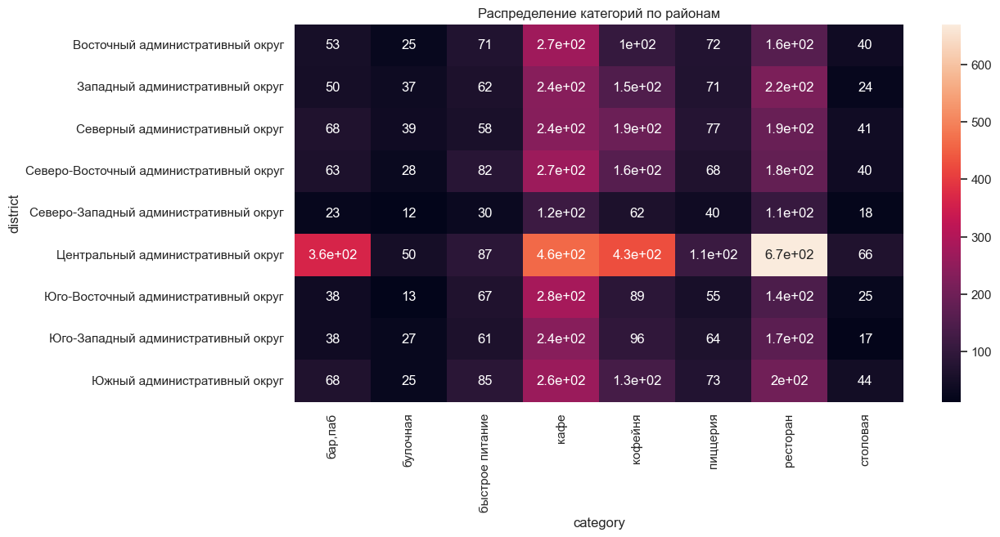

In [25]:
heatmap(data, 'district', 'category', 'address', 'count', 'Распределение категорий по районам')

Больше всего выделяется центральный округ. Там больше всего заведений и больше всего именно ресторанов. Кафе во всех округах лежат в дианопозе от 200 до 500. Также можно заметить, что больше всего пабов именно в центральном районе.



Теперь проверим количество посадочных мест по категориям.

Т.к. у нас большое количество пропусков по данному признаку, то нам необходимо эти данные обработать. во-первых обнулим пропуски, Во-вторых изменим тип данных.

In [26]:
data['seats']=data['seats'].fillna(-1)
data['seats']=data['seats'].astype(int)

Создадим датафрейм с данными без нулевых значений

In [27]:
seats_tmp = data.query('seats >= 0')
seats_tmp.seats.describe()

count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

In [28]:
seats_tmp.groupby('category').agg({'seats': 'describe'})

seats                                                  \
                  count        mean         std  min   25%   50%    75%   
category                                                                  
бар,паб           468.0  124.532051  145.011574  0.0  48.0  82.5  150.0   
булочная          148.0   89.385135   97.685844  0.0  25.0  50.0  120.0   
быстрое питание   349.0   98.891117  106.611739  0.0  28.0  65.0  140.0   
кафе             1217.0   97.365653  117.922464  0.0  35.0  60.0  120.0   
кофейня           751.0  111.199734  127.837772  0.0  40.0  80.0  144.0   
пиццерия          427.0   94.496487  112.282703  0.0  30.0  55.0  120.0   
ресторан         1268.0  121.869874  123.838539  0.0  48.0  86.0  150.0   
столовая          164.0   99.750000  122.951453  0.0  40.0  75.5  117.0   

                         
                    max  
category                 
бар,паб          1288.0  
булочная          625.0  
быстрое питание  1040.0  
кафе             1288.0  
кофейня          1288.0  
пиццерия         1288.0  
ресторан         1288.0  
столовая         1200.0

стоит обратить внимание, что средние значения значительно отличаются от медианных. Это объясняется тем, что очень многие значения приходятся на махсимальные и  конечно при многих максимальных значениях среднее всегда будет отличаться от медианы

Визуализируем данные


In [29]:
fig = px.box(seats_tmp,
       y = 'seats',
       x = 'category',
       title = 'Распределение посадочных мест по категориям',
       template = 'ggplot2',
       color = 'category'
       )
fig.update_layout(xaxis_title = 'Категория',
                  yaxis_title = 'Количество посадочных мест')

Итак, можно сказать, что верхнаяя граница почти всех заведений около 300 посадочных мест. Медианные значения колеблются от 50 до 80 в зависимости от категории заведения. Наибольшими количеством мест  обладают, кофейни, предприятия быстрого питания, рестораны и бары. Меньше всего мест  у булочных, кафе и столовых. Также можно отметить бальшое количество выбросов у ресторанов,кафе,пиццерий,баров,пабов и кофеен

Выведем среднее и медианное значения, чтобы понять, как они различаются. Затем построим heatmap, чтобы понять, как среднее количество мест по категориям зависит от: местоположения(района) ,сети и круглосуточности.

In [30]:
data.pivot_table(index='category', values='seats', aggfunc=['mean', 'median'])

,mean,median
,seats,seats
category,,
"бар,паб",75.796078,40.0
булочная,51.253906,9.0
быстрое питание,56.814262,10.0
кафе,49.362221,0.0
кофейня,58.633404,6.0
пиццерия,63.418641,30.0
ресторан,75.334640,42.0
столовая,51.453968,6.0


Можно заметить, что среднее и медианные значения достаточно сильно отличаются. Посмотрим по графикам от каких параметров может зависеть.

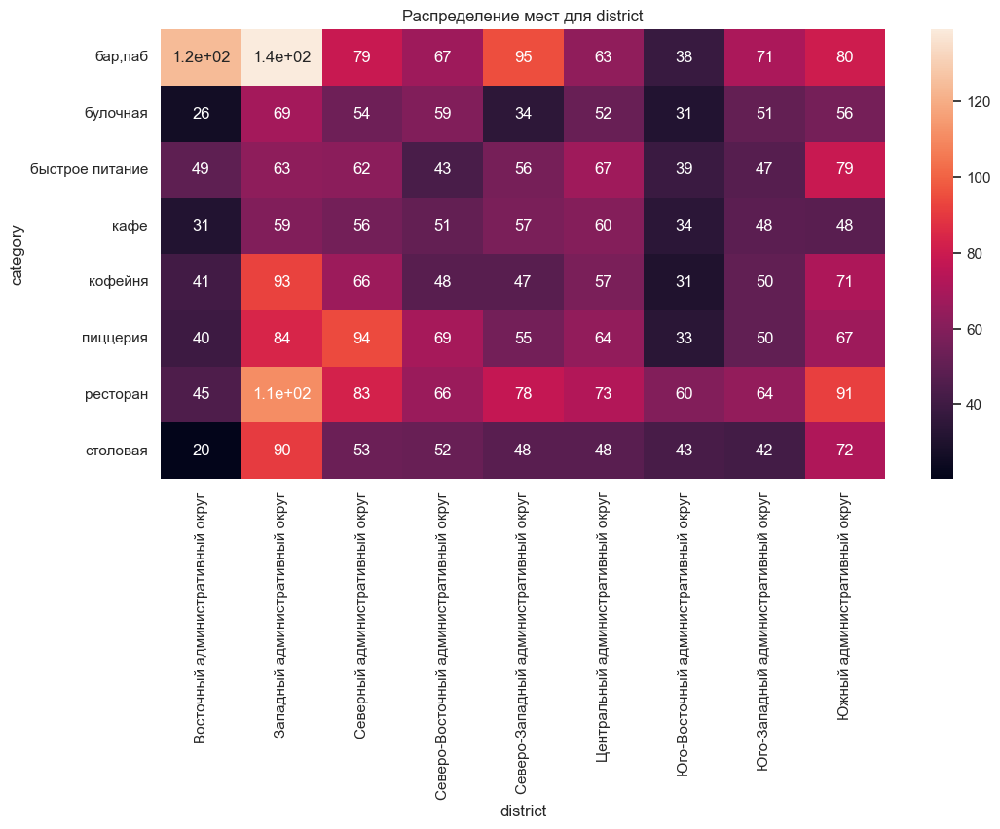

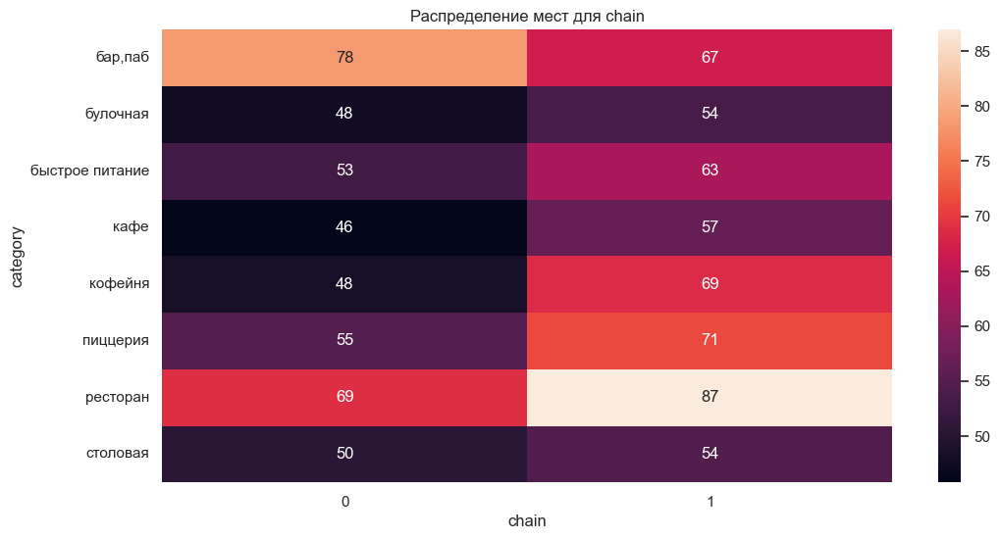

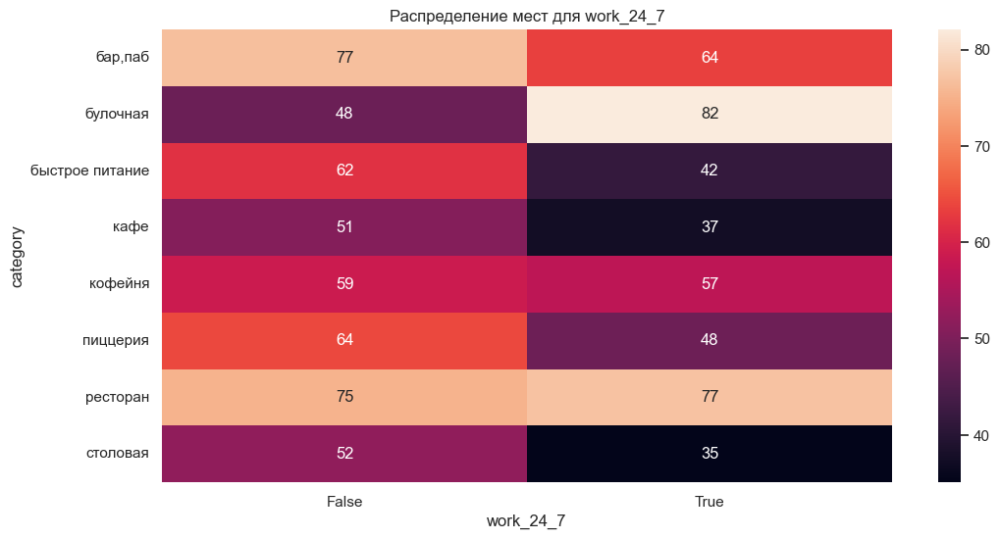

In [31]:
values = ['district', 'chain', 'work_24_7']
for i in values:
    heatmap(data, 'category', i, 'seats', 'mean', ('Распределение мест для ' + i))

В среднем больше всего посадочных мест в барах и рестоанах, при этом самое большое количество мест в Западном округе. Из несетевых заведений больше всего посадочных мест также в рестаранах и пабах, а в сетевых заведениях лидируют рестораны, однако также много посадочных мест в кофейнях. В среднем в круглосуточных ресторанах больше всего мест, а не в круглосуточных- больше всего мест в барах.

Теперь изучим рейтинги заведений по категориям.

In [32]:
data.rating.describe()

count    8403.000000
mean        4.229894
std         0.470426
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

In [33]:
data.groupby('category').agg({'rating': 'describe'})

rating                                             
                  count      mean       std  min  25%  50%  75%  max
category                                                            
бар,паб           765.0  4.387712  0.380143  1.1  4.3  4.4  4.6  5.0
булочная          256.0  4.268359  0.386303  1.3  4.2  4.3  4.4  5.0
быстрое питание   603.0  4.050249  0.560949  1.1  3.9  4.2  4.3  5.0
кафе             2377.0  4.123896  0.566200  1.0  4.0  4.2  4.4  5.0
кофейня          1413.0  4.277282  0.372250  1.4  4.1  4.3  4.4  5.0
пиццерия          633.0  4.301264  0.336162  1.0  4.2  4.3  4.4  5.0
ресторан         2041.0  4.290348  0.413237  1.0  4.2  4.3  4.5  5.0
столовая          315.0  4.211429  0.454205  1.0  4.1  4.3  4.4  5.0

Визуализируем данные

In [34]:
fig = px.box(data,
       y = 'rating',
       x = 'category',
       title = 'Рейтинг заведений по категориям',
       template = 'ggplot2',
       color = 'category'
       )
fig.update_layout(xaxis_title = 'Категория',
                  yaxis_title = 'Рейтинг')

Выводы следующие:
1.У кафе и баров размах доходит до 5 баллов, у остальных же категорий предприятий питания 5 баллов считаются выбросами, что говорит о том, что предприятий доходящих до 5 баллов рейтинга очень мало.
2. Наиболее высокие оценки у баров, хуже всего по оценкам пользователей ситуация у предприятий быстрого питания
3.У Кафе, Ресторанов и Фаст фудных больше всего выбросов с негативными оценками

Для каждого из округов посчитаем средний рейтинг заведений

In [35]:
rating_df = data.groupby('district', as_index=False)['rating'].agg('mean').sort_values(by = 'rating', ascending = False)
rating_df

,district,rating
5,Центральный административный округ,4.377520
2,Северный административный округ,4.239822
4,Северо-Западный административный округ,4.208802
8,Южный административный округ,4.184417
1,Западный административный округ,4.181647
0,Восточный административный округ,4.174185
7,Юго-Западный административный округ,4.172920
3,Северо-Восточный административный округ,4.147978
6,Юго-Восточный административный округ,4.101120


In [36]:
map(data, 'district', 'rating', 'mean', 'Средний рейтинг заведений по районам')

Теперь рассмотрим рейтинги по районам.

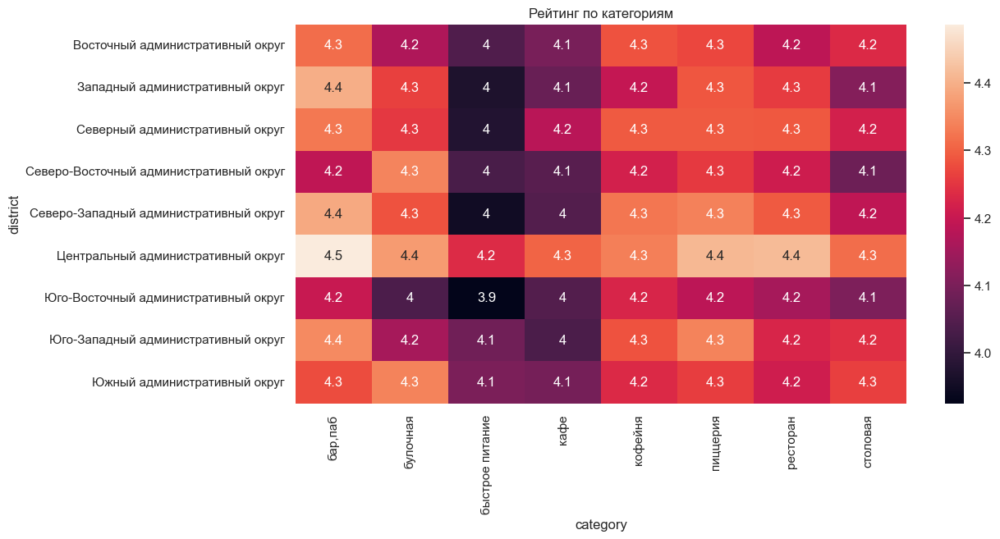

In [37]:
heatmap(data, 'district', 'category', 'rating', 'mean', 'Рейтинг по категориям')

Здесь уже видна разница. Рейтинги у быстрого питания в некоторых районах ниже 4. Самые высокие оценки в Центральном районе, но даже в здесь оценки у быстрого питания самые низкие. Оценки выше 4,4 есть у баров, пиццерий и ресторанов. Средние оценки у кафе не в центральном районе ниже 4,3.

Однако среднее значение не всегда показательно. Рассмотрим также медианное значение рейтинга по регионам.

In [38]:
map(data, 'district', 'rating', 'median', 'Медианный рейтинг заведений по районам')

Самые хорошие рейтинги в Центральном районе

Отображение всех заведений датасета

In [39]:
moscow_lat, moscow_lng = 55.751244, 37.618423
# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# создаём пустой кластер, добавляем его на карту
marker_cluster = MarkerCluster().add_to(m)
df = data
def create_clusters(row):
    # сохраняем URL-адрес изображения со значком торгового центра с icons8,
    # это путь к файлу на сервере icons8
    icon_url = 'https://img.icons8.com/ios/256/restaurant-building.png'
    # создаём объект с собственной иконкой размером 30x30
    icon = CustomIcon(icon_url, icon_size=(30, 30))

    # создаём маркер с иконкой icon и добавляем его в кластер
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['rating']}",
        icon=icon,
    ).add_to(marker_cluster)

# применяем функцию для создания кластеров к каждой строке датафрейма
df.apply(create_clusters, axis=1)

# выводим карту
m

Вывод: В центре самый высокий средний рейтиг заведений. Хуже дела обстоят на Южном административном округе в ЮЗАО, СВАО и ЮВАО.

После изучения категории заведений можно сделать следующие выводы:

Больше всего по Москве кафе, ресторанов и кофеен;
Самый популярный район - Центральный;
Больше всего посадочных мест нужно чтобы открыть ресторан или бар. Меньше всего мест нужно для булочных.
По категориями средний рейтинг не сильно отличается, однако у быстрого питания они ниже всего, а у баров выше всего.

Проведем анализ количественных показателей сетевых и несетевых заведений
.

На данном этапе стоит рассмотреть сетевые заведения. Рассмотреть сколько их по отношению к несетевым и посмотреть, как зависит сеть от разных параметров

In [40]:
data['is_chain'] = data['chain'].map({ 0:'несетевое', 1:'сетевое'})

count_chain = data.is_chain.value_counts().reset_index()
count_chain = count_chain.rename(columns={'index': 'type', 'is_chain': 'count'})
count_chain

,count,count
0,несетевое,5199
1,сетевое,3204


In [41]:
count_chain = data.pivot_table(index=['chain'], values='address', aggfunc='count').sort_values(by = 'address', ascending=False)
count_chain.columns= ['values']

name_chain = count_chain.index
values = count_chain['values']

fig = go.Figure(data=[go.Pie(labels=name_chain, values=values)])
fig.update_layout(title='Распределение количества заведений по сетям')
fig.show()

Сетевых заведений 38,1% от общего числа заведений.

Сравним по категориям количество сетевых и несетевых заведений

In [42]:
chain_type_tmp = data.groupby(['category','is_chain']).agg({'chain': 'count'}).reset_index()
chain_type_tmp = chain_type_tmp.rename(columns={'index': 'category', 'is_chain': 'type', 'chain': 'count'})
chain_type_tmp

,category,type,count
0,"бар,паб",несетевое,596
1,"бар,паб",сетевое,169
2,булочная,несетевое,99
3,булочная,сетевое,157
4,быстрое питание,несетевое,371
5,быстрое питание,сетевое,232
6,кафе,несетевое,1598
7,кафе,сетевое,779
8,кофейня,несетевое,693
9,кофейня,сетевое,720


Визуализирем эти данные для наглядности

In [43]:
fig = px.bar(chain_type_tmp,
             x='category',
             y= 'count',
             title = 'Количество сетевых и несетевых заведений по категориям в Москве',
             template = 'ggplot2',
             color='type', barmode='group')
fig.update_layout(xaxis_title = 'Категория и тип заведения',
                  yaxis_title = 'Количество заведений')
fig.update_traces(hovertemplate = 'Категория заведения : %{x} <br>Количество: %{y}')

fig.show()

Анализ количества сетевых и несетевых заведений по категориям показывает, что лидерами по колиичеству сетевых заведений являются кафе, рестораны, кофейни. Меньше всего сетей у столовых. Причем у таких категорий как булочная, кофейня и пиццерия количество сетевых заведений больше чем несетвых.

Теперь рассмотрим сами сетевые заведения.

In [44]:
chain_places = data[data['chain'] == 1]

In [45]:
chain = ['в сетевых заведениях', 'в несетевых заведениях']
titles = ['Количесво заведений по категориям ', 'Количество заведений по округам ', 'Количество заведений по круглосуточности ']
index = ['category', 'district', 'work_24_7']
for i in range(len(index)):
    bar(chain_places, index[i], 'name', 'count', (str(titles[i]) + str(chain[0])))

Итак, больше всего сетевых заведений являются кафе, кофейнями и ресторанами и больше всего их расположено в центральном районе. В основном они не круглосуточные

Теперь рассмотрим несетевые заведения.

In [46]:
not_chain_places = data[data['chain'] == 0]

In [47]:
for i in range(len(index)):
    bar(not_chain_places, index[i], 'name', 'count', (str(titles[i]) + str(chain[1])))


Несетевыми также часто являются некруглосуточные кафе в ценральном районе

Сгруппируем данные по названию заведения и категории и посмотрим, какие заведения предстовляют собой самую большую сеть.

In [48]:
top_20 = data.query('is_chain == "сетевое"').groupby(['name', 'category']).agg({'address':'count'}).reset_index().sort_values(by=['address'],ascending=False, inplace=False).head(20)
top_20

,name,category,address
1125,шоколадница,кофейня,119
496,домино'с пицца,пиццерия,76
489,додо пицца,пиццерия,74
205,one price coffee,кофейня,71
1141,яндекс лавка,ресторан,69
72,cofix,кофейня,65
241,prime,ресторан,49
617,кофепорт,кофейня,42
632,кулинарная лавка братьев караваевых,кафе,39
962,теремок,ресторан,36


Итого мы получили наиболее крупные сети. В то же время необходимо учесть, что такие названия как "кафе", "ресторан", "шаурма", "чайхона" и "Столовая" - общедоступные названия. И заведения с таким названием сетью не является. Избавимся от этих заведений с такими названиями для определения 20 самых больших сетевиков.

In [49]:
fig = px.bar(top_20 ,
             x='name',
             y= 'address',
             title = 'Количество точек у крупных сетевиков Москвы',
             template = 'ggplot2',
             #color='category',
             # barmode='group'
            )
fig.update_layout(xaxis_title = 'Название заведения',
                 yaxis_title = 'Количество заведений')
fig.update_traces(hovertemplate = 'Название заведения : %{x} <br>Количество: %{y}')

fig.show()

Получили, что в основном крупными сетевиками являются кофейни и пицерии, что по сути неудивительно.

Итак

Несетевых заведений больше, чем сетевых, сетевые заведения занимают 38,1% от общего числа заведений;
Самое большое количество сетевых заведений являются кафе, ресторанами и кофейнями, располагаются чаще всего в центральном районе и не являются круглосуточными;
Самое большое количество несетвых заведений - некруглосуточные кафе в центральном районе.

Приступим к анализу рынка по административным округам г. Москва

In [50]:
data.district.value_counts()

district
Центральный административный округ         2242
Северный административный округ             899
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64

Лидером по количеству заведений является Центральный округ( что также неудивительно), наименьшее количество заведений расположено на Северо-западе .

Выведем топ-15 сетевых заведений

In [51]:
count_category = pd.DataFrame(chain_places.groupby('name').count().sort_values(by='category', ascending=False).head(15)['category'])
count_category.columns= ['values']

name_cat = count_category.index
values = count_category['values']

fig = go.Figure(data=[go.Pie(labels=name_cat, values=values, pull=[0.2, 0.1, 0.05])])
fig.update_layout(title='Топ-15 сетевых заведений')
fig.show()

Итак, самыми популярными по Москве являются Шоколадница, Домино'с пицца и Додо Пицца

Теперь посмотрим на категории этих заведений.

In [52]:
top = pd.DataFrame(chain_places.groupby('name').count().sort_values(by='category', ascending=False).head(15)['category']).index
pd.DataFrame(chain_places.query('name in @top').groupby('name')['category'].unique())

,category
name,
cofefest,"[кофейня, кафе]"
cofix,[кофейня]
one price coffee,[кофейня]
prime,"[ресторан, кафе]"
буханка,"[булочная, кофейня, кафе]"
додо пицца,[пиццерия]
домино'с пицца,[пиццерия]
кофепорт,[кофейня]
кулинарная лавка братьев караваевых,[кафе]


Как было выяснено ранее, больше всего ресторанов, кафе и кофеен, однако также есть 2 большие сети пиццерий по городу.*** Вероятнее всего это связано с размером этих сетей, значит конкурировать с ними будет сложно.***

Рассмотрим количество заведений по категориям в административных округах

In [53]:
data.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7,is_chain
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,-1,улица Дыбенко,False,несетевое
1,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4,улица Дыбенко,False,несетевое
2,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45,Клязьминская улица,False,несетевое
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,-1,улица Маршала Федоренко,False,несетевое
4,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148,Правобережная улица,False,сетевое


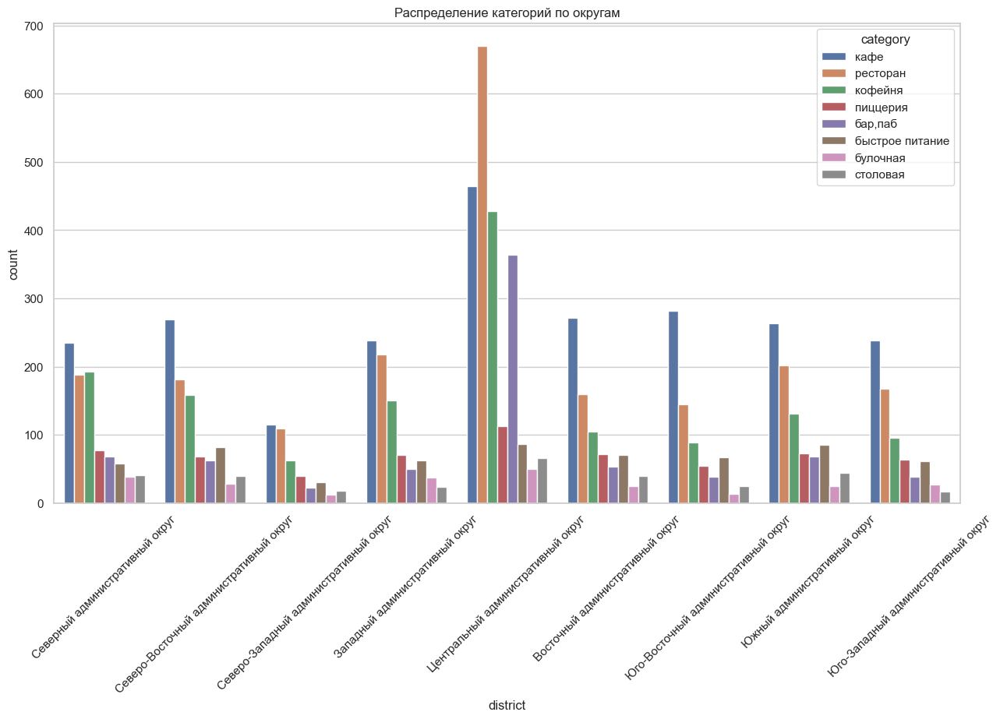

In [54]:
plt.figure(figsize=(15, 8))
sns.countplot(x='district', hue='category', data=data)
plt.xticks(rotation=45)
plt.title('Распределение категорий по округам')
plt.show()

 Во всех округах, кроме центрального на лидирующими по количеству заведений является такая категория как кафе. В центральном же округе рестораны занимают лидирующую позицию. Распределение количества заведений по категориям в административных округах очень похоже между собой. Выделяются в этом плане только Центр Москвы.

Теперь изучим улицы Москвы. Для этого выведем все заведения на карте с помощью кластеров, затем найдём топ-15 улиц по количеству заведений. Далее найдём улицы, на которых находится только один объект общепита.

In [55]:
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# создаём пустой кластер, добавляем его на карту
marker_cluster = MarkerCluster().add_to(m)

# пишем функцию, которая принимает строку датафрейма,
# создаёт маркер в текущей точке и добавляет его в кластер marker_cluster
def create_clusters(row):
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['category']}",
    ).add_to(marker_cluster)

# применяем функцию create_clusters() к каждой строке датафрейма
data.apply(create_clusters, axis=1)

# выводим карту
m

Рассмотрим Топ-20 улиц по количеству заведений

In [56]:
named_st = data.loc[data['street'] != 'untitled']
top20street = named_st.groupby('street').agg({'street':'count'}).rename(columns={'street':'count'}).reset_index().sort_values(by = 'count', ascending = False).head(20)
top20street

,street,count
1090,проспект Мира,183
773,Профсоюзная улица,122
1087,проспект Вернадского,108
525,Ленинский проспект,107
523,Ленинградский проспект,95
373,Дмитровское шоссе,88
455,Каширское шоссе,77
298,Варшавское шоссе,76
524,Ленинградское шоссе,70
550,МКАД,65


Визуализируем данные

In [57]:
fig = px.bar(top20street,
             y='count',
             x= 'street',
             title = 'Топ 20 улиц по количеству заведений',
             template = 'ggplot2')
fig.update_layout(xaxis_title = 'Название улицы',
                 yaxis_title = 'Количество заведений')
fig.update_traces(hovertemplate = 'Название Улицы : %{x} <br>Количество: %{y}')

fig.show()

Мы получили топ 20 улиц, где находится больше всего заведений питания. Очевидно, что по количеству мест лидируют крупные городские транспортные артерии - шоссе, проспекты.

Рассмотрим количество заведений по категориям на этих улицах.

Создадим отдельный датафрейм, где будут находиться данные на заведения только с выше перечисленных улиц

In [58]:
top_streets = top20street.street.tolist()
top_st_df = data.query("street in @top_streets")

top_st_df.street.unique()

array(['Дмитровское шоссе', 'МКАД', 'Ленинградское шоссе',
       'Алтуфьевское шоссе', 'проспект Мира', 'Ленинградский проспект',
       'Измайловское шоссе', 'Кутузовский проспект',
       'Пресненская набережная', 'Ленинский проспект',
       'Волгоградский проспект', 'Пятницкая улица',
       'проспект Вернадского', 'улица Вавилова', 'Профсоюзная улица',
       'проспект Андропова', 'Люблинская улица', 'улица Миклухо-Маклая',
       'Варшавское шоссе', 'Каширское шоссе'], dtype=object)

In [59]:
top_st_category = top_st_df.groupby(['street','category'], as_index=False)['name'].agg('count')
top_st_category = top_st_category.rename(columns={'name':'count'})
top_st_category

,street,category,count
0,Алтуфьевское шоссе,"бар,паб",5
1,Алтуфьевское шоссе,булочная,1
2,Алтуфьевское шоссе,быстрое питание,5
3,Алтуфьевское шоссе,кафе,13
4,Алтуфьевское шоссе,кофейня,9
...,...,...,...
140,улица Миклухо-Маклая,быстрое питание,4
141,улица Миклухо-Маклая,кафе,21
142,улица Миклухо-Маклая,кофейня,4
143,улица Миклухо-Маклая,пиццерия,2


Визуализируем данные

In [60]:
fig = px.bar(top_st_category,
             y='street',
             x= 'count',
             title = 'Количество заведений по категориям в Топ-20 улицах',
             template = 'ggplot2',
             color='category', barmode='stack')
fig.update_layout(yaxis_title = 'Улица, категория заведения',
                  xaxis_title = 'Количество заведений')

fig.show()

Наибольшие доли находящихся на этих улицах категорий заведений - Ресторан, Кафе, Кофейни. Эти данные совпадают с тем, что визуально пропорция долей категорий заведений по всем данным является примерно такой же.

In [61]:
top_st_data = data.pivot_table(index='street', values='name', aggfunc='count').sort_values(by='name', ascending=False).head(15)
# соделаем отдельно список топ-15 улиц
top_st = top_st_data.index
top_st_data

,name
street,
проспект Мира,183
Профсоюзная улица,122
проспект Вернадского,108
Ленинский проспект,107
Ленинградский проспект,95
Дмитровское шоссе,88
Каширское шоссе,77
Варшавское шоссе,76
Ленинградское шоссе,70


Построим график распределения количества заведений и их категорий по улицам.

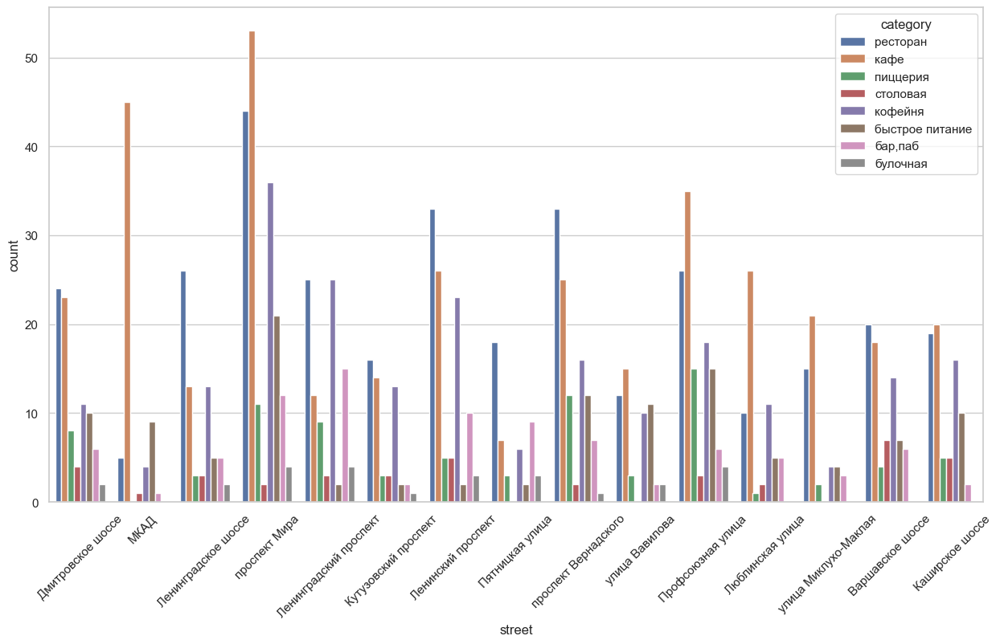

In [62]:
top_st_data = data.query('street in @top_st')
plt.figure(figsize=(15, 8))
sns.countplot(x='street', hue='category', data=top_st_data)
plt.xticks(rotation=45)
plt.show()

Как уже было выяснено ранее, по имеющимся данным нет улицы определённой категории. Однако можно выявить следующие закономерности:

Больше всего кафе на улицах: МКАД, проспект Мира,Профсоюзная улица, Люблинская улица. Больше всего ресторанов: Ленинградское шоссе, Ленинградский проект, Ленинский проект, Пятницкая улица, проспект Вернадского. Больше всего кафе и ресторанов: Дмитровское шоссе, Кутузовский проект, улица Вавилова, Варшавское шоссе, Каширское шоссе.

Однако важно помнить, что не всегда количество заведений определяет то, популярна ли она в плане питания в общем. Стоит посмотреть на размеры улиц, чтобы узнать, на каких улицах много заведений потому что они популярны, а на каких много заведений, потому что они большие.

In [63]:
# создадим список с цветами
color = ['blue', 'red', 'green', 'purple', 'orange', 'brown', 'pink', 'gray', 'cyan', '#ADFF2F', '#CD5C5C', '#800000', '#FFA07A', '#20B2AA', '#00FA9A']
color_name = ['синий', 'красный', 'зелёный', 'фиолетовый', 'оранжевый', 'коричневый', 'розовый', 'серый', 'бирюзовый', 'салатовый', 'коралловый', 'тёмно-красный', 'светло-оранжевый', 'морской-голубой', 'ярко-салатовый']
# создадим таблицу, где присвоим кажой улице свой цвет
street_data = pd.DataFrame()
street_data['street'] = top_st
street_data['color'] = color
street_data['color_name'] = color_name
street_data

,street,color,color_name
0,проспект Мира,blue,синий
1,Профсоюзная улица,red,красный
2,проспект Вернадского,green,зелёный
3,Ленинский проспект,purple,фиолетовый
4,Ленинградский проспект,orange,оранжевый
5,Дмитровское шоссе,brown,коричневый
6,Каширское шоссе,pink,розовый
7,Варшавское шоссе,gray,серый
8,Ленинградское шоссе,cyan,бирюзовый
9,МКАД,#ADFF2F,салатовый


In [64]:
# moscow_lat - широта центра Москвы, moscow_lng - долгота центра Москвы
moscow_lat, moscow_lng = 55.751244, 37.618423

# создаём карту Москвы
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
for i in range(len(top_st)):
    d = top_st_data[top_st_data['street'] == top_st[i]][['lat', 'lng']]
    folium.PolyLine(d, color=color[i]).add_to(m)
m

Как можно заметить, МКАД появился в топе не из-за насыщенности заведениями, а из-за своего размера. Также большими можно назвать Дмитровское шоссе и Варшавское шоссе, однако лидеры топа, например проспект Мира, Профсоюзная улица, проспект Вернадского, Ленинский проспект, относительно Москвы не большие. Поэтому их по-прежнему можно считать популярными.

Теперь изучим улицы, на которых находится только 1 заведение.

In [65]:
tmp = named_st.street.value_counts().to_frame().reset_index()
tmp = tmp.rename(columns={'index':'street' ,'street':'count'})
tmp = tmp.query('count == 1')
tmp

,count,count
990,улица Бусиновская Горка,1
991,Прибрежный проезд,1
992,парк Левобережный,1
993,Угличская улица,1
994,ландшафтный заказник Лианозовский,1
...,...,...
1443,улица Шкулёва,1
1444,улица Артюхиной,1
1445,Кузьминская улица,1
1446,Новороссийская улица,1


Итого у нас получилось 458 улицы, на которых располагается только одно заведение питания. Создадим отдельный датафрейм, с такими заведениями и изучим их

In [66]:
# 1. Убедимся, что столбец 'street' существует в data.
# Если его нет, создаем его заново из 'address'.
if 'street' not in data.columns:
    # Проверяем, есть ли столбец 'address', чтобы избежать ошибки
    if 'address' in data.columns:
        # Создаем столбец 'street', разбивая адрес по запятой и пробелу.
        # Берем второй элемент (индекс 1), так как первый — это "Москва".
        # Используем .str[1], чтобы избежать ошибок, если адрес короче.
        data['street'] = data['address'].astype(str).str.split(', ').str[1]
        # Если вдруг адрес был просто "Москва" и второго элемента нет, будет NaN.
        # Это нормально, мы их отфильтруем.
    else:
        # Если нет ни street, ни address, мы не можем продолжить.
        # В этом случае создаем пустой столбец, чтобы избежать падения.
        data['street'] = None

# 2. Теперь, когда столбец 'street' гарантированно есть, 
# пересоздаем список улиц с одним заведением (lonley_st) из data.
# Это безопаснее, чем использовать старую переменную tmp, которая могла устареть.
# Находим все улицы, где только 1 заведение.
street_counts = data['street'].value_counts()
lonley_st = street_counts[street_counts == 1].index.tolist()

# 3. Создаем итоговый датафрейм, фильтруя data по этому списку.
lonley_df = data[data['street'].isin(lonley_st)].copy()

# 4. Выводим результат (для проверки)
print(f"Количество 'одиноких' заведений: {len(lonley_df)}")
lonley_df.head()

Количество 'одиноких' заведений: 458


,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7,is_chain
15,дом обеда,столовая,"москва, улица бусиновская горка, 2",Северный административный округ,пн-пт 08:30–18:30; сб 10:00–20:00,55.885890,37.493264,4.1,средние,Средний счёт:300–500 ₽,400.0,NaN,0,180,улица Бусиновская Горка,False,несетевое
21,7/12,кафе,"москва, прибрежный проезд, 7",Северный административный округ,"ежедневно, 10:00–22:00",55.876805,37.464934,4.5,NaN,NaN,NaN,NaN,0,-1,Прибрежный проезд,False,несетевое
25,в парке вкуснее,кофейня,"москва, парк левобережный",Северный административный округ,"ежедневно, 10:00–21:00",55.878453,37.460028,4.3,NaN,NaN,NaN,NaN,1,-1,парк Левобережный,False,сетевое
58,coffeekaldi's,кофейня,"москва, угличская улица, 13, стр. 8",Северо-Восточный административный округ,"ежедневно, 09:00–22:00",55.900316,37.570558,4.1,средние,Средний счёт:500–800 ₽,650.0,NaN,1,-1,Угличская улица,False,сетевое
60,чебуречная история,кофейня,"москва, ландшафтный заказник лианозовский",Северо-Восточный административный округ,"ежедневно, 10:00–22:00",55.899845,37.570488,4.9,NaN,NaN,NaN,NaN,1,-1,ландшафтный заказник Лианозовский,False,сетевое


In [67]:
tmp = lonley_df.groupby('district').agg({'name':'count'}).rename(columns={'name':'count'}).reset_index().sort_values(by = 'count' ,ascending=False)
tmp

,district,count
5,Центральный административный округ,145
3,Северо-Восточный административный округ,55
0,Восточный административный округ,52
2,Северный административный округ,52
8,Южный административный округ,43
6,Юго-Восточный административный округ,39
1,Западный административный округ,35
4,Северо-Западный административный округ,19
7,Юго-Западный административный округ,18


Опять визуализируем данные

In [68]:
fig = px.bar(tmp,
             y='count',
             x= 'district',
             title = 'Количество "одноулицевых" заведений питания по округам',
             template = 'ggplot2')
fig.update_layout(xaxis_title = 'Округ',
                 yaxis_title = 'Количество заведений')
fig.update_traces(hovertemplate = 'Округ : %{x} <br>Количество: %{y}')

fig.show()

Лидером среди округов по таким одиноким заведениям является ЦАО. Вероятно, что это связано с тем, что в центре Москвы, есть очень маленькие улицы, на которых больше одного заведения питания и не поместится.

Теперь проверим на рейтинги этих заведений.

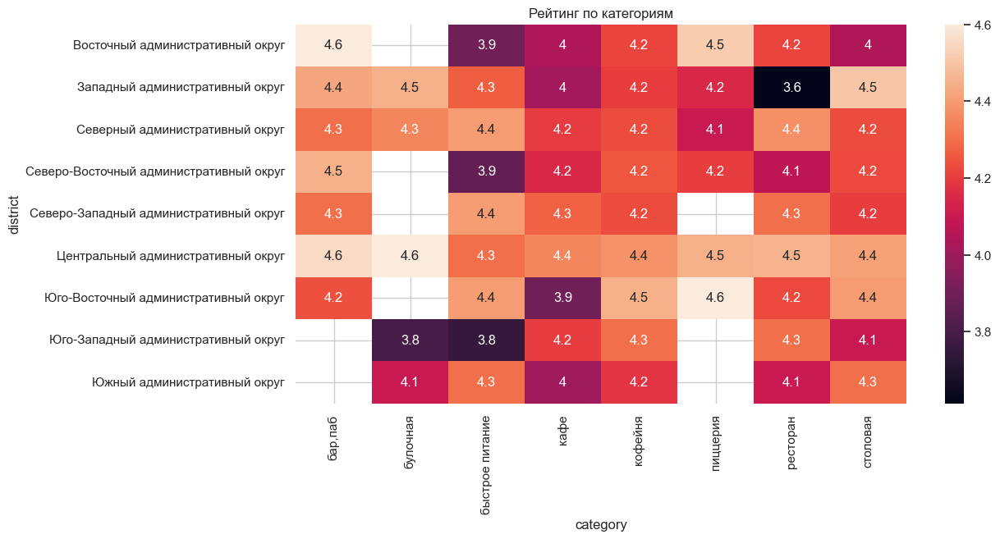

In [69]:
heatmap(lonley_df, 'district', 'category', 'rating', 'mean', 'Рейтинг по категориям')

Рейтинги в некоторых районах отсутствуют

Можно заметить, что рейтинги достаточно высокие. Вероятнее всего это связано с тем, что у посетителей нет альтернатив. Возможно, открывать заведение на таких улицах будет выгодно в плане рейтинга.

Теперь посмотрим, как связан рейтинг, сети и категории.

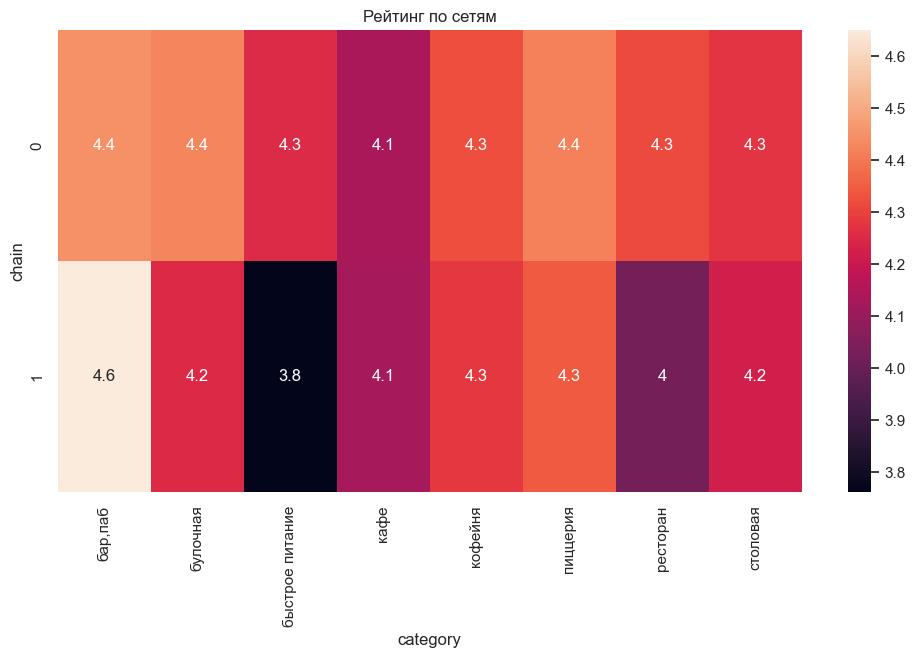

In [70]:
heatmap(lonley_df, 'chain', 'category', 'rating', 'mean', 'Рейтинг по сетям')

У сетевых баров достаточно высокие рейтинги. Вероятнее всего конкурировать с ними будет сложно.

Рассмотрим рейтинг по круглосуточности

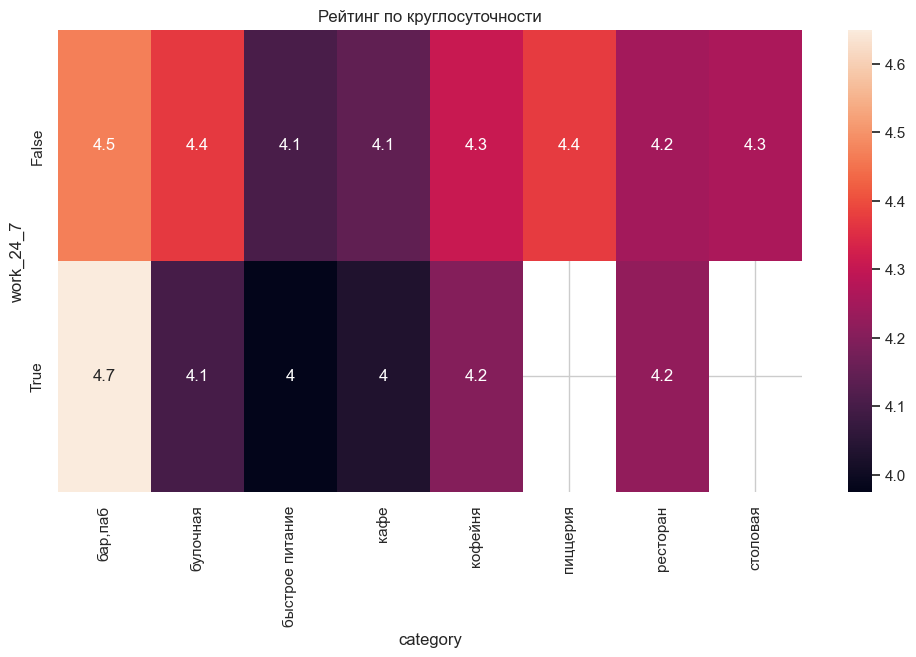

In [71]:
heatmap(lonley_df, 'work_24_7', 'category', 'rating', 'mean', 'Рейтинг по круглосуточности')

Если у некруглосуточных заведений на этих улицах рейтинг может колебаться от 4.1 до 4.5. В круглосуточных отсутствует рейтинг у пиццерий и столовых. Самый высокий рейтинг у баров

Рассмотрим соотношение категорий "одноулицевых" заведений по Москве

In [72]:
tmp['percentage'] = (tmp['count'] / 437 *100).round(2)
tmp.sort_values(by = 'percentage', ascending = False)
tmp

,district,count,percentage
5,Центральный административный округ,145,33.18
3,Северо-Восточный административный округ,55,12.59
0,Восточный административный округ,52,11.90
2,Северный административный округ,52,11.90
8,Южный административный округ,43,9.84
6,Юго-Восточный административный округ,39,8.92
1,Западный административный округ,35,8.01
4,Северо-Западный административный округ,19,4.35
7,Юго-Западный административный округ,18,4.12


Визуализируем данные

In [73]:
fig = px.bar(tmp,
             x='district',
             y= 'percentage',
             title = 'Доля "одноулицевых" заведений по округам в Москве',
             template = 'ggplot2',
             barmode='group')
fig.update_layout(xaxis_title = 'Округ',
                  yaxis_title = 'Доля заведений')
fig.update_traces(hovertemplate = 'Округ : %{x} <br>Доля: %{y}')

fig.show()

очень сильно выделяется ЦАО

Рассмотрим распределение  одноулицевых заведений по категориям и по административным округам

In [74]:
lonley_pt = lonley_df.groupby(['district','category']).agg({'name':'count'}).rename(columns={'name':'count'}).reset_index()
fig = px.bar(lonley_pt,
             x='district',
             y= 'count',
             title = 'Количество "одноулецевых" заведений по категориям в разрезе округов',
             template = 'ggplot2',
             color='category', barmode='group')
fig.update_layout(xaxis_title = 'Округ, категория заведения',
                  yaxis_title = 'Количество заведений')

fig.show()

Как мы видим в ЦАО значительно преобладают кафе, рестораны, кофейни и бары с пабами. В остальных округах заметное преобладание имеют кафе.

Проведем анализ среднего чека заведений

In [75]:
middle_avg_bill_df = data.query('middle_avg_bill.notnull()')
middle_avg_bill_df.middle_avg_bill = middle_avg_bill_df.middle_avg_bill.astype(int)

In [76]:
dist_mid_avg_bill = middle_avg_bill_df.groupby('district').agg({'middle_avg_bill':'median'}).rename(columns={'middle_avg_bill':'median'}).sort_values(by = 'median' ,ascending=False).round(1).reset_index()
dist_mid_avg_bill

,district,median
0,Западный административный округ,1000.0
1,Центральный административный округ,1000.0
2,Северо-Западный административный округ,700.0
3,Северный административный округ,650.0
4,Юго-Западный административный округ,600.0
5,Восточный административный округ,575.0
6,Северо-Восточный административный округ,500.0
7,Южный административный округ,500.0
8,Юго-Восточный административный округ,450.0


Теперь рассмотрим медианную стоимость заказа по округам.

In [77]:
map(data, 'district', 'middle_avg_bill', 'median', 'Медианные стоимости заказа в рублях')

В центральном районе, западных и в юго-западных районах цены самые высокие. В других регионах цены значительно ниже. То есть чем дальше район от центра, тем ниже цены во всех направлениях, кроме западного и юго-западного.

Выводы раздела

В Москве предствлены 8 категорий заведений: 'кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб', 'быстрое питание', 'булочная', 'столовая'. Больше всего кафе и ресторанов и кофеен, меньше всего столовых и булочных Количество посадочных мест варируется от категории заведения. Верхнаяя граница почти всех заведений около 300 посадочных мест. Медианные значения колеблются от 50 до 80 в зависимости от категории заведения. Наибольшими количеством мест статистически обладают кофейни, предприятия быстрого питания, рестораны и бары. Меньше всего мест статистически у булочных, кафе и столовых. Несетевых заведений в Москве - 5199, сетевых - 3204 Лидерами по колиичеству сетевых заведений являются кафе, рестораны, кофейни. Меньше всего сетей у столовых. Интересно то, что у таких категорий как булочная, кофейня и пиццерия количество сетевых заведений больше чем несетвых. В процессе исследования мы нашли топ 20 самых крупных сетевиков: 'шоколадница', "домино'с пицца", 'додо пицца', 'one price coffee','яндекс лавка', 'cofix', 'prime', 'кофепорт', 'кулинарная лавка братьев караваевых', 'теремок', 'cofefest','буханка', 'drive café', 'кофемания', 'cinnabon' и др. В данном исследовании мы рассматриваем 8 округов Москвы. Больше всего заведений питания расположились в центре Москвы, в остальных округах предприятий питания меньше более чем в 2 раза. Рассмотрев количество категорй кафе по округам можно отметить, что во всех округах, кроме центрального на лидирующими по количеству заведений является такая категория как кафе. В центральном же округе рестораны занимают лидирующую позицию после кафе. Стоит также отметить, что распределение количества заведений по категориям в административных округах очень похоже между собой. Выделяются в этом плане только Центр Москвы. Таже в процессе исследования мы рассмотрели рейтинг заведений по категориям. Наиболее высокие оценки у баров, хуже всего по оценкам пользователей ситуация у предприятий быстрого питания Также рассмотрели рейтинг заведений в разрезе админимстративных округов. Выше всего средняя оценка в ЦАО (4.4), ниже всего в СВАО и ЮВАО (4.2) Нам удалось найти топ 20 улиц с самым большим количеством заведений. Стоит отметить, что рекордсменами по количеству мест являются крупные городские транспортные артерии - шоссе, проспекты Также нашли 458 улиц, на которых находится только одно заведение. Значимая часть таких улиц находится в центре, где улочки сами по себе небольшие.

Детализируем исследование: открытие столовых т.к. их очень небольшое количество и при правильно выбранном районе и ценовой категории данное заведение должно быть высоко рентабельным.



In [78]:
data.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7,is_chain
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,-1,улица Дыбенко,False,несетевое
1,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4,улица Дыбенко,False,несетевое
2,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45,Клязьминская улица,False,несетевое
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,-1,улица Маршала Федоренко,False,несетевое
4,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148,Правобережная улица,False,сетевое


В этом вопросе  необходимо ответить на следующие ворпосы:

1. Сколько всего столовых в датасете? В каких округах их больше всего, каковы особенности их расположения?
2. Есть ли круглосуточные столовые?
3. Какие у столовых рейтинги? Как они распределяются по округам?
4. На какую средний счет стоит ориентироваться при открытии и почему?

Для исследовния  понадобится отдельный датафрейм, где будут содержаться только столовые

In [79]:
dining_room = data[data['category'] == 'столовая']
print('Всего в Москве', dining_room.shape[0], 'столовых')

Всего в Москве 315 столовых


Рассмотрим их распределение по округам.

In [80]:
din_dist= dining_room.groupby('district').agg({'name': 'count'}).reset_index().rename(columns={'name':'count'}).sort_values(by = 'count', ascending=False)
din_dist

,district,count
5,Центральный административный округ,66
8,Южный административный округ,44
2,Северный административный округ,41
0,Восточный административный округ,40
3,Северо-Восточный административный округ,40
6,Юго-Восточный административный округ,25
1,Западный административный округ,24
4,Северо-Западный административный округ,18
7,Юго-Западный административный округ,17


Визуализируем данные

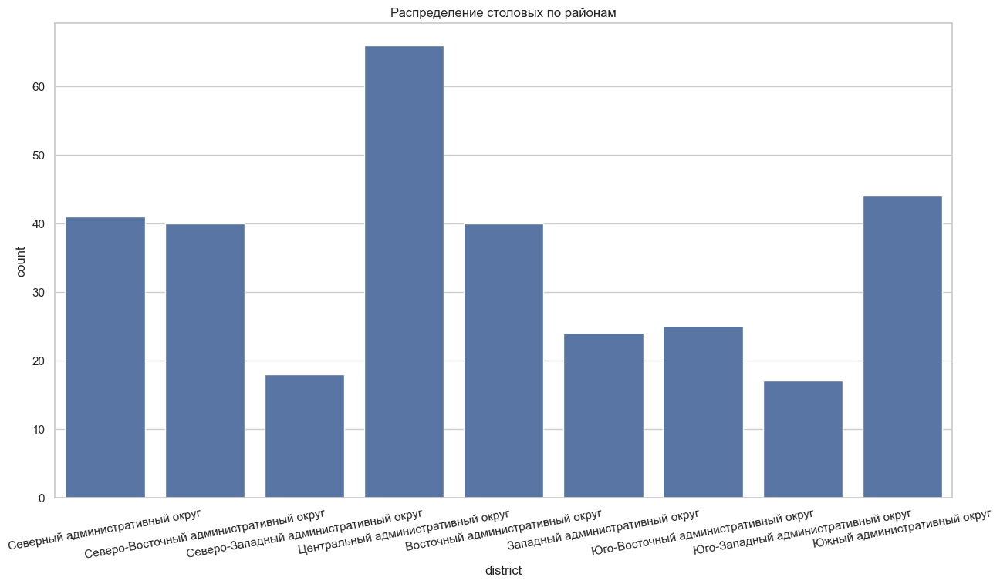

In [81]:
plt.figure(figsize=(15, 8))
sns.countplot(x='district', data=dining_room)
plt.xticks(rotation=10)
plt.title('Распределение столовых по районам')
plt.show()

Для удобства посмотрим на карте.

In [82]:
map(dining_room, 'district', 'name', 'count', 'Количество кофеен по районам')

Итого можно увидеть, что в Москве открыто 315 столовых. Больше всего столовых находится в ЦАО, меньше всего в СВАО, ЮВАО и ВАО. В среднем количество столовых варьируется от 20 до 40 на округ

Изучим круглосуточные столовые.

In [83]:
def round_the_clock2 (value):
    if 'ежедневно, круглосуточно'in value:
        return "Круглосуточное"
    else:
        return "Не круглосуточное"

dining_room['round_the_clock'] = dining_room['hours'].apply(round_the_clock2)

In [84]:
tmp = dining_room.groupby('round_the_clock').agg({'name': 'count'}).reset_index().rename(columns={'name':'count'}).sort_values(by = 'count', ascending=False)
tmp

,round_the_clock,count
1,Не круглосуточное,303
0,Круглосуточное,12


Итого мы видим, что в Москве всего 12 столовых работают круглосуточно.

Визулизируем это соотношение

In [85]:
fig = px.pie(tmp, values='count', names='round_the_clock', title='Соотношение столовых работающих круглосуточно и не круглосуточно')
fig.show()

Только чуть меньше 4% столовых работает круглосуточно

Посмотрим как их количество зависит от района.

In [86]:
map(dining_room, 'district', 'work_24_7', 'sum', 'Количество круглосуточных столовых')

Больше всего круглосуточных кофеен в центре. В остальных районах их почти нет. Однако некоторое количество присутствует в северо восточной части Москвы

Изучим рейтинги столовых.

In [87]:
din_rating =  dining_room.groupby('district').agg({'rating': 'describe'}).reset_index()
din_rating

district rating                           \
                                            count      mean       std  min   
0         Восточный административный округ   40.0  4.232500  0.511101  2.5   
1          Западный административный округ   24.0  4.112500  0.706068  1.0   
2          Северный административный округ   41.0  4.217073  0.269168  3.5   
3  Северо-Восточный административный округ   40.0  4.082500  0.581725  1.4   
4   Северо-Западный административный округ   18.0  4.188889  0.364432  3.5   
5       Центральный административный округ   66.0  4.315152  0.271317  3.6   
6     Юго-Восточный административный округ   25.0  4.104000  0.722542  1.3   
7      Юго-Западный административный округ   17.0  4.241176  0.264714  3.5   
8             Южный административный округ   44.0  4.261364  0.315651  3.2   

                            
     25%   50%    75%  max  
0  4.100  4.30  4.525  5.0  
1  4.000  4.25  4.325  4.8  
2  4.000  4.20  4.400  4.9  
3  4.075  4.20  4.400  4.9  
4  4.000  4.20  4.350  4.9  
5  4.100  4.30  4.500  5.0  
6  4.100  4.20  4.400  4.9  
7  4.100  4.20  4.400  4.6  
8  4.200  4.30  4.400  4.9

In [88]:
print('Медианный рейтинг всех столовых равен',dining_room['rating'].median() , '. Средний рейтинг:',dining_room['rating'].mean())

Медианный рейтинг всех столовых равен 4.3 . Средний рейтинг: 4.211428571428572


Визуализируем данные

In [89]:
fig = px.box(data.query('category == "столовая"'),
       y = 'rating',
       x = 'district',
       title = 'Рейтинг столовых по округам',
       template = 'ggplot2',
       color = 'district'
       )
fig.update_layout(xaxis_title = 'Округ',
                  yaxis_title = 'Рейтинг')

Лучше всего с рейтингом в таких округах как: ВАО, ЦАО, СЗАО

Посмотрим как рейтинги распределены на карте.

In [90]:
map(dining_room, 'district', 'rating', 'median', 'Медианный рейтинг заведений по округам')

В северо-западном округах, а также в ЮЗАО и ЮВАО самые низкие рейтинги

Дополнительно изучим количество посадочных мест.

In [91]:
din_seats = dining_room.query('seats >= 0')

Визуализируем данные

In [92]:
fig = px.box(din_seats,
       y = 'seats',
       x = 'district',
       title = 'Распределение посадочных мест в столовых по округам',
       template = 'ggplot2',
       color = 'district'
       )
fig.update_layout(xaxis_title = 'Округ',
                  yaxis_title = 'Количество посадочных мест')

Построим еще один график, исключая выбросы

In [93]:
fig = px.box(din_seats.query('seats < 300'),
       y = 'seats',
       x = 'district',
       title = 'Распределение посадочных мест в столовых по округам',
       template = 'ggplot2',
       color = 'district'
       )
fig.update_layout(xaxis_title = 'Округ',
                  yaxis_title = 'Количество посадочных мест')

Медианы по округам рознятся от 42 до 100 посадочных мест. В зависимости от округа в котором планируется к открытию кофейня можно будет детальнее рассмотреть количество посадочных мест.

In [94]:
map(dining_room, 'district', 'seats', 'median', 'Медианное количество посадочных мест')

Самые большое количество посадочных мест у столовых в  в ЮАО.

Рассмотрим средний чек в столовой

In [95]:
data.head()

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,work_24_7,is_chain
0,wowфли,кафе,"москва, улица дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",55.878494,37.478860,5.0,NaN,NaN,NaN,NaN,0,-1,улица Дыбенко,False,несетевое
1,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",55.875801,37.484479,4.5,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN,0,4,улица Дыбенко,False,несетевое
2,хазри,кафе,"москва, клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",55.889146,37.525901,4.6,средние,Средний счёт:от 1000 ₽,1000.0,NaN,0,45,Клязьминская улица,False,несетевое
3,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",55.881608,37.488860,5.0,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0,0,-1,улица Маршала Федоренко,False,несетевое
4,иль марко,пиццерия,"москва, правобережная улица, 1б",Северный административный округ,"ежедневно, 10:00–22:00",55.881166,37.449357,5.0,средние,Средний счёт:400–600 ₽,500.0,NaN,1,148,Правобережная улица,False,сетевое


In [96]:
dining_room_avg = dining_room.query('middle_avg_bill.notnull()')
dining_room_avg.groupby('district').agg({'middle_avg_bill': 'describe'})

middle_avg_bill              \
                                                  count        mean   
district                                                              
Восточный административный округ                   20.0  364.700000   
Западный административный округ                    12.0  565.000000   
Северный административный округ                    22.0  337.500000   
Северо-Восточный административный округ            21.0  325.238095   
Северо-Западный административный округ             11.0  298.636364   
Центральный административный округ                 44.0  319.886364   
Юго-Восточный административный округ               14.0  288.928571   
Юго-Западный административный округ                 9.0  311.666667   
Южный административный округ                       28.0  291.392857   

                                                                            \
                                                 std    min     25%    50%   
district                                                                     
Восточный административный округ          200.411970  125.0  265.00  300.0   
Западный административный округ          1004.059940  175.0  250.00  300.0   
Северный административный округ           200.693737  225.0  250.00  300.0   
Северо-Восточный административный округ   220.014069  175.0  250.00  275.0   
Северо-Западный административный округ     42.549436  250.0  260.00  300.0   
Центральный административный округ         95.305437  200.0  261.25  300.0   
Юго-Восточный административный округ       81.787214  150.0  241.25  275.0   
Юго-Западный административный округ        60.000000  200.0  300.00  305.0   
Южный административный округ               60.223866  185.0  250.00  282.5   

                                                         
                                            75%     max  
district                                                 
Восточный административный округ         381.25  1000.0  
Западный административный округ          306.25  3750.0  
Северный административный округ          325.00  1200.0  
Северо-Восточный административный округ  300.00  1250.0  
Северо-Западный административный округ   320.00   375.0  
Центральный административный округ       338.75   775.0  
Юго-Восточный административный округ     325.00   450.0  
Юго-Западный административный округ      350.00   400.0  
Южный административный округ             321.25   450.0

Визуализируем данные

In [97]:
fig = px.box(data.query('category == "столовая"'),
       y = 'middle_avg_bill',
       x = 'district',
       title = 'Средний чек в столовой по округам',
       template = 'ggplot2',
       color = 'district'
       )
fig.update_layout(xaxis_title = 'Категория',
                  yaxis_title = 'Рейтинг')

Исключим одинокие  выбросы для более корректного отображения визуализации графика.

In [98]:
fig = px.box(data.query('category == "столовая" & middle_avg_bill < 400'),
       y = 'middle_avg_bill',
       x = 'district',
       title = 'Средний чек в столовой по округам',
       template = 'ggplot2',
       color = 'district'
       )
fig.update_layout(xaxis_title = 'Категория',
                  yaxis_title = 'Рейтинг')

 Мы видим, что в средней чек в столовой составляет до 280 рублей. В разных округах сумма немного варируется. Например дороже пообедать обойдетсяв СЗАО и ЦАО. Дешевле всего в СВАО

In [99]:
print('Стоит ориентироваться на цену от', int(dining_room['middle_avg_bill'].median()), 'до', round(dining_room['middle_avg_bill'].mean()), 'рублей')

Стоит ориентироваться на цену от 300 до 335 рублей


In [100]:
map(dining_room, 'district', 'middle_avg_bill', 'median', 'Медианная стоимость чека в столовой')

Рекомендации:

Самое большое количество столовых, как не удивительно, в центре. меньше всего их на на юго-западе. В данном случае чуствуется явный дефецит такого рода заведений в ЮЗАО.
Очень мало круглосуточных столовых в районах кроме центрального  и северо-востока столицы. Нет смысла искать персонал и оборудовать всё под круглосуточное заведение, так как конкурентного преимущества по сути это не даст.Также нет смысла делать круглосуточные столовые на окраинах , потому что это в основном спальные районы и спрос на такого рода заведения будет очеь низким. Люди, которые живут или ездят в центр ночью наверняка знают, что большая часть столовых находится именно в центре и не будут замечать новую круглосуточную столовую на окраине.
Рейтинг столовых в ЮЗАО достаточно высок -4,25,  что говорит о довольно большой популярности и востребованности
Средний чек в столовой должен быть  от 300 до 335 рублей. Такая цена позволит сохранять конкурентоспособность, так как она не будет в низком ценовом сигменте и не будет в высоком.

Выводы
В ходе данной работы были проделаны следующие шаги:

Изучена структура данных;
проверено наличие дубликатов;
изучены пропуски. Выяснено, что их заполнение будет затруднительным;
проведён анализ данных всех категорий заведений;
изучены данные о столовых.